# 5-2 分布与抽样

请选择 `Python (da-course)` 内核，从 `notebooks/` 打开。本课用 `orders.csv` 和 `penguins.csv` 理解总体与样本、标准误、中心极限定理（CLT）、95% 置信区间以及截断抽样偏差。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

读取数据并查看基本规模。

In [2]:
orders = pd.read_csv("../data/shop/orders.csv", encoding="utf-8-sig")
penguins = pd.read_csv("../data/public/penguins.csv")
pay = orders.loc[orders["status"].eq("已完成"), "pay_amount"].copy()
print("已完成订单数：", len(pay), "企鹅非空体重数：", penguins["body_mass_g"].notna().sum())

已完成订单数： 13996 企鹅非空体重数： 342


## 1. 中心极限定理：右偏总体抽样后的均值分布

即使单笔订单金额明显右偏，反复随机抽取 `n = 50` 笔求均值，这批样本均值的分布会接近对称的钟形，且离散度（标准误）约为 `std / sqrt(50)`。

In [3]:
rng = np.random.default_rng(42)
vals = pay.to_numpy()
sample_means = np.array([rng.choice(vals, size=50, replace=True).mean() for _ in range(500)])
print(f"500 次抽样均值的均值：{sample_means.mean():.2f} 元（总体均值：{vals.mean():.2f}）")
print(f"500 次抽样均值的标准差：{sample_means.std(ddof=1):.2f} 元（理论标准误：{pay.std() / np.sqrt(50):.2f}）")

500 次抽样均值的均值：127.65 元（总体均值：127.49）
500 次抽样均值的标准差：17.95 元（理论标准误：18.68）


画出“单笔订单右偏分布”与“样本均值钟形分布”的对比图。

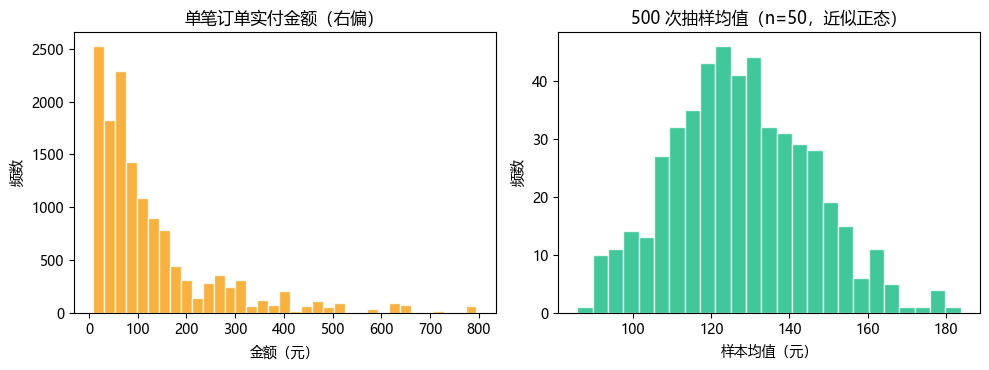

In [4]:
setup_chinese_font()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(vals, bins=35, color="#f59e0b", alpha=0.8, edgecolor="white")
axes[0].set(title="单笔订单实付金额（右偏）", xlabel="金额（元）", ylabel="频数")
axes[1].hist(sample_means, bins=25, color="#10b981", alpha=0.8, edgecolor="white")
axes[1].set(title="500 次抽样均值（n=50，近似正态）", xlabel="样本均值（元）", ylabel="频数")
fig.tight_layout()
plt.show()

## 2. 标准误与 95% 置信区间

样本量越大，标准误 `SE = std / sqrt(n)` 越小，均值估计越稳。大样本下常用 `mean ± 1.96 * SE` 给出近似 95% 置信区间。

In [5]:
se = pay.std() / np.sqrt(len(pay))
print(f"全量均值：{pay.mean():.2f}，标准误：{se:.2f}，95% CI：[{pay.mean() - 1.96 * se:.2f}, {pay.mean() + 1.96 * se:.2f}]")

全量均值：127.49，标准误：1.12，95% CI：[125.30, 129.68]


## 练习 5-2.1 企鹅体重的均值、标准差与标准误

去掉 `penguins["body_mass_g"]` 中的缺失值后，计算 `mean`、`std`（默认 `ddof=1`）和标准误 `se = std / sqrt(n)`，存入字典 `penguin_se`。

In [6]:
mass = penguins["body_mass_g"].dropna()
penguin_se = {
    "mean": mass.mean(),
    "std": mass.std(),
    "se": mass.std() / np.sqrt(len(mass)),
}
check("5-2.1", penguin_se)

True

## 练习 5-2.2 用固定种子模拟抽样分布

使用 `rng = np.random.default_rng(2026)`，从已完成订单 `pay_amount` 数组中循环 500 次，每次有放回抽取 `size=50` 并算均值；返回这 500 个均值的均值 `mean_of_means` 和样本标准差 `std_of_means`（`ddof=1`）。

In [7]:
vals_ex = orders.loc[orders["status"].eq("已完成"), "pay_amount"].to_numpy()
rng_ex = np.random.default_rng(2026)
means_ex = np.array([rng_ex.choice(vals_ex, size=50, replace=True).mean() for _ in range(500)])
clt_answer = {
    "mean_of_means": float(means_ex.mean()),
    "std_of_means": float(means_ex.std(ddof=1)),
}
check("5-2.2", clt_answer)

True

## 练习 5-2.3 已完成订单均价的 95% 置信区间

计算全年已完成订单 `pay_amount` 均值的近似 95% 置信区间：`ci_low = mean - 1.96 * se`，`ci_high = mean + 1.96 * se`。

In [8]:
s_ci = orders.loc[orders["status"].eq("已完成"), "pay_amount"]
se_ci = s_ci.std() / np.sqrt(len(s_ci))
ci_answer = {
    "ci_low": float(s_ci.mean() - 1.96 * se_ci),
    "ci_high": float(s_ci.mean() + 1.96 * se_ci),
}
check("5-2.3", ci_answer)

True

## 练习 5-2.4 体会非随机截断偏差

比较全年已完成订单均价与 `orders.iloc[:3000]`（按时间排在前面的前 3000 行）中已完成订单均价的绝对差值 `abs(...)`。

In [9]:
full_mean = orders.loc[orders["status"].eq("已完成"), "pay_amount"].mean()
head_done = orders.iloc[:3000]
head_mean = head_done.loc[head_done["status"].eq("已完成"), "pay_amount"].mean()
bias_diff = float(abs(full_mean - head_mean))
check("5-2.4", bias_diff)

True